# EDA del corpus documental

Calidad de extracción, longitudes de texto y cobertura temática aproximada por términos.

Al final: **lectura, insights y decisiones** (qué soporta A1, qué no se puede afirmar aún).


In [1]:
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent

import pandas as pd
import matplotlib.pyplot as plt

INV = ROOT / "data" / "processed" / "corpus" / "inventario_documental.csv"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
df = pd.read_csv(INV)
for col in ("n_pages", "chars", "words"):
    df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0).astype(int)


## Calidad de extracción

estado_extraccion
ok                 11
weak_or_scanned     1
Name: count, dtype: int64
texto_extraible:
texto_extraible
True    12
Name: count, dtype: int64


,doc_id,words,chars,estado_extraccion,notas
9,D010,128,819,weak_or_scanned,NaN


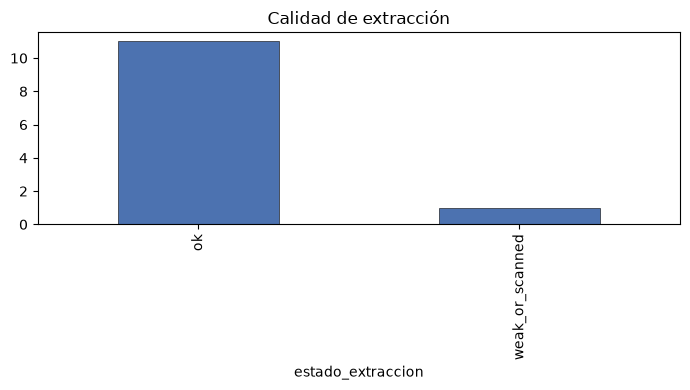

In [2]:
print(df["estado_extraccion"].value_counts())
print("texto_extraible:")
print(df["texto_extraible"].value_counts())
d010 = df[df["doc_id"] == "D010"]
if not d010.empty:
    display(d010[["doc_id", "words", "chars", "estado_extraccion", "notas"]])
else:
    print("D010 no está en el inventario.")

fig, ax = plt.subplots(figsize=(7, 4))
df["estado_extraccion"].value_counts().plot(
    kind="bar", ax=ax, color="#4C72B0", edgecolor="black", linewidth=0.4
)
ax.set_title("Calidad de extracción")
ax.set_xlabel("estado_extraccion")
fig.tight_layout()
p = FIG_DIR / "eda_calidad_extraccion.png"
fig.savefig(p, dpi=140)
plt.show()


In [3]:
import re

THEME_PATTERNS: dict[str, re.Pattern[str]] = {
    "matricula": re.compile(r"matricul", re.I),
    "asistencia": re.compile(r"inasistenc|asistenc", re.I),
    "evaluacion": re.compile(r"evaluaci[oó]n|examen|parcial|sustitutor", re.I),
    "creditos": re.compile(r"cr[eé]dito", re.I),
    "prerrequisitos": re.compile(r"prerrequis|pre-?requis", re.I),
    "convalidacion": re.compile(r"convalid", re.I),
    "tramites_grados": re.compile(r"bachiller|t[ií]tulo|grado", re.I),
    "becas": re.compile(r"beca", re.I),
    "admision": re.compile(r"admisi[oó]n", re.I),
    "tarifas": re.compile(r"tarif|pension|pago", re.I),
    "malla_plan": re.compile(r"plan de estudi|malla|curricul", re.I),
    "calendario": re.compile(r"calendario acad[eé]mico|periodo acad[eé]mico", re.I),
}
TEXT_DIR = ROOT / "data" / "interim" / "extracted_text"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)


## Longitudes de texto

,n_pages,chars,words
count,12.000000,12.000000,12.000000
mean,8.500000,27874.416667,4060.833333
std,6.403124,20115.536634,2957.720309
min,1.000000,819.000000,128.000000
25%,4.500000,13118.000000,1967.750000
50%,7.500000,22037.500000,3177.000000
75%,11.500000,47365.250000,6913.750000
max,20.000000,57927.000000,8623.000000


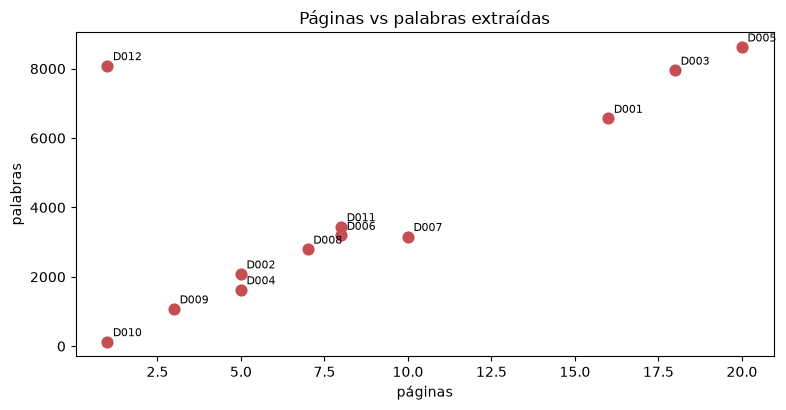

In [4]:
display(df[["doc_id", "n_pages", "chars", "words"]].describe())

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.scatter(df["n_pages"], df["words"], s=60, c="#C44E52")
for _, r in df.iterrows():
    ax.annotate(
        r["doc_id"],
        (r["n_pages"], r["words"]),
        fontsize=8,
        xytext=(4, 4),
        textcoords="offset points",
    )
ax.set_title("Páginas vs palabras extraídas")
ax.set_xlabel("páginas")
ax.set_ylabel("palabras")
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_paginas_vs_palabras.png", dpi=140)
plt.show()


## Cobertura temática (hits por documento)

In [5]:
from collections import Counter

theme_doc_counts: Counter[str] = Counter()
hit_rows: list[dict[str, int | str]] = []

for _, doc in df.iterrows():
    doc_id = str(doc["doc_id"])
    path = TEXT_DIR / f"{doc_id}.txt"
    row: dict[str, int | str] = {"doc_id": doc_id}
    if not path.exists():
        for theme in THEME_PATTERNS:
            row[theme] = 0
        hit_rows.append(row)
        continue
    text = path.read_text(encoding="utf-8", errors="replace")
    for theme, pat in THEME_PATTERNS.items():
        n = len(pat.findall(text))
        row[theme] = n
        if n > 0:
            theme_doc_counts[theme] += 1
    hit_rows.append(row)

hits_df = pd.DataFrame(hit_rows).set_index("doc_id")
display(hits_df)
print("Documentos con al menos un hit por tema:")
for theme in sorted(THEME_PATTERNS):
    print(f"  {theme}: {theme_doc_counts[theme]} / {len(df)}")


,matricula,asistencia,evaluacion,creditos,prerrequisitos,convalidacion,tramites_grados,becas,admision,tarifas,malla_plan,calendario
doc_id,,,,,,,,,,,,
D001,7,9,65,9,0,6,37,0,4,4,8,3
D002,23,0,3,7,1,3,0,4,2,15,5,1
D003,1,5,15,2,0,0,71,2,9,1,8,1
D004,2,0,3,4,0,0,7,0,1,53,1,1
D005,1,0,29,2,0,0,233,0,1,1,6,0
D006,2,1,24,3,0,5,11,11,47,0,0,1
D007,3,2,18,5,0,0,6,92,0,12,0,0
D008,2,3,8,0,0,0,3,0,0,0,2,0
D009,0,0,6,4,2,23,8,0,0,0,7,0


Documentos con al menos un hit por tema:
  admision: 8 / 12
  asistencia: 6 / 12
  becas: 5 / 12
  calendario: 6 / 12
  convalidacion: 6 / 12
  creditos: 11 / 12
  evaluacion: 11 / 12
  malla_plan: 9 / 12
  matricula: 10 / 12
  prerrequisitos: 2 / 12
  tarifas: 9 / 12
  tramites_grados: 10 / 12


## Matriz Sí / Parcial / No y heatmap

,tema,D001,D002,D003,D004,D005,D006,D007,D008,D009,D010,D011,D012
0,matricula,Parcial,Sí,Parcial,Parcial,Parcial,Parcial,Parcial,Parcial,No,No,Parcial,Parcial
1,asistencia,Sí,No,Parcial,No,No,Parcial,Parcial,Parcial,No,No,No,Sí
2,evaluacion,Sí,Parcial,Sí,Parcial,Sí,Sí,Sí,Sí,Parcial,No,Sí,Sí
3,creditos,Sí,Parcial,Parcial,Parcial,Parcial,Parcial,Parcial,No,Parcial,Parcial,Parcial,Sí
4,prerrequisitos,No,Parcial,No,No,No,No,No,No,Parcial,No,No,No
5,convalidacion,Parcial,Parcial,No,No,No,Parcial,No,No,Sí,No,Parcial,Parcial
6,tramites_grados,Sí,No,Sí,Parcial,Sí,Sí,Parcial,Parcial,Sí,No,Sí,Sí
7,becas,No,Parcial,Parcial,No,No,Sí,Sí,No,No,No,No,Parcial
8,admision,Parcial,Parcial,Sí,Parcial,Parcial,Sí,No,No,No,No,Sí,Sí
9,tarifas,Parcial,Sí,Parcial,Sí,Parcial,No,Sí,No,No,Parcial,Parcial,Sí


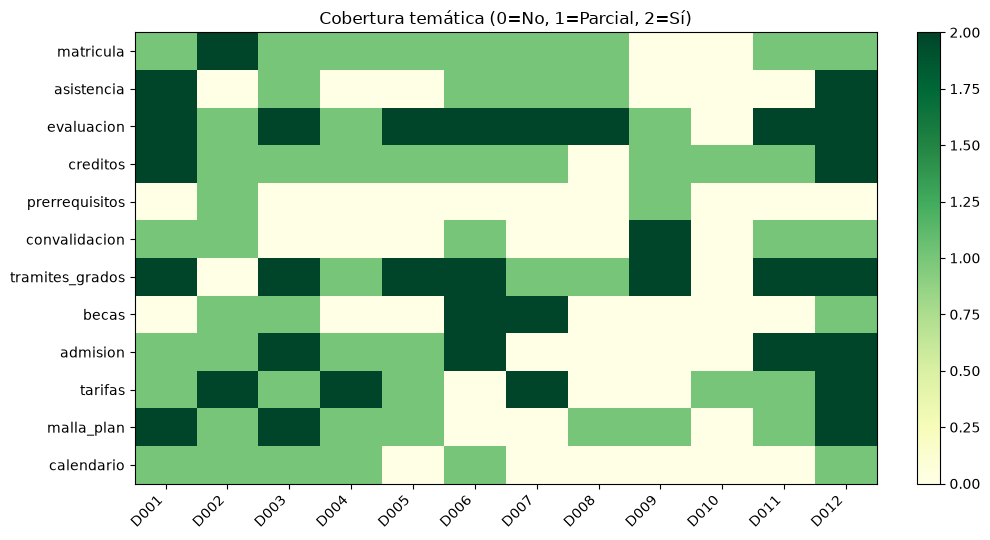

In [6]:
rows: list[dict[str, str]] = []
for theme in THEME_PATTERNS:
    row: dict[str, str] = {"tema": theme}
    for _, doc in df.iterrows():
        doc_id = str(doc["doc_id"])
        path = TEXT_DIR / f"{doc_id}.txt"
        if not path.exists():
            row[doc_id] = "No"
            continue
        text = path.read_text(encoding="utf-8", errors="replace")
        n = len(THEME_PATTERNS[theme].findall(text))
        if n >= 8:
            row[doc_id] = "Sí"
        elif n >= 1:
            row[doc_id] = "Parcial"
        else:
            row[doc_id] = "No"
    rows.append(row)

cov = pd.DataFrame(rows)
cov.to_csv(FIG_DIR / "eda_matriz_cobertura.csv", index=False)
display(cov)

score = (
    cov.set_index("tema")
    .replace({"Sí": 2, "Parcial": 1, "No": 0})
    .apply(pd.to_numeric, errors="coerce")
    .fillna(0)
)
fig, ax = plt.subplots(figsize=(10, 5.5))
im = ax.imshow(score.to_numpy(dtype=float), aspect="auto", cmap="YlGn")
ax.set_xticks(range(len(score.columns)))
ax.set_xticklabels(score.columns, rotation=45, ha="right")
ax.set_yticks(range(len(score.index)))
ax.set_yticklabels(score.index)
ax.set_title("Cobertura temática (0=No, 1=Parcial, 2=Sí)")
fig.colorbar(im, ax=ax, fraction=0.03)
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_matriz_cobertura.png", dpi=140)
plt.show()


## Conclusiones

- **Calidad:** 11/12 con extracción `ok`. El corpus público es usable para recuperación textual pero hay una pieza rota (D010)**.
- **Longitudes:** mediana ~7–8 páginas y ~3 000 palabras. Hay reglamentos densos (p. ej. D005) y piezas cortas. En el scatter, D010 queda abajo: archivo presente no implica texto recuperable.
- **Cobertura lexical fuerte:** evaluación, créditos, matrícula, trámites/grados, tarifas, admisión aparecen en varios documentos. Eso respalda un piloto A1 (RAG normativo).
- **Cobertura lexical débil:** prerrequisitos casi ausentes (2/12). «Malla/plan» y «calendario» salen por menciones sueltas, no porque exista malla oficial ni calendario del ciclo en el inventario.

| Decisión | Por qué |
|----------|--------|
| Construir índice A1 con D001–D009, D011, D012 | Texto suficiente y temas N bien representados |
| No mezclar malla demo dentro del índice de reglamentos | La malla es herramienta/grafo (A3), no otro PDF más |
| Tratar consultas de prerrequisitos / avance como R con evidencia limitada | El corpus público no opera esa estructura |
| No usar la matriz de hits como métrica de calidad del sistema | Solo indica presencia de palabras; no mide respuesta correcta ni vigencia |
| Pedir OCR o fuente alternativa para D010 antes de usarlo en retrieval | 128 palabras no sostienen preguntas de proceso de matrícula |

### Insight

El EDA del corpus separa dos problemas: (1) extracción de texto, casi resuelta en el piloto; (2) cobertura institucional, aún abierta. El experimento de enrutamiento puede arrancar en norma+FAQ.

### Pendientes

| Aspecto | Efecto |
|---------|--------|
| Sin malla oficial | Tipo R incompleto |
| Sin calendario dedicado | Preguntas de fechas frágiles |
| D010 débil | Falsa sensación de cobertura en matrícula operativa |
| Hits ≠ vigencia | Un término puede aparecer sin responder la consulta |
